Cell 1 — Imports, configuration, seeding, output directory

In [9]:
# ============================================================
# CELL 1 — Imports, configuration, seeding, output directory
# ============================================================
import os, sys, json, math, random, time, subprocess, warnings
from collections import Counter, defaultdict
from datetime import datetime

try:
    import transformers, sklearn, matplotlib, pandas  # noqa
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "transformers", "scikit-learn", "matplotlib", "pandas"], check=True)

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from transformers import BertModel, BertTokenizerFast, get_cosine_schedule_with_warmup
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, precision_recall_fscore_support)

warnings.filterwarnings("ignore", category=UserWarning)


# >>>>>>>>>>>>>>>>>>>>>>>>>>> EDIT THIS <<<<<<<<<<<<<<<<<<<<<<<
# Folder that contains (directly or in sub-folders) the six JSON files.
DATA_DIR = "/kaggle/input/datasets/sumiayasharif/bangladeshi-ontology"
# >>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>

JSON_FILES = ["dataset_new.json", "e_commerce1 (1).json", "educationDomain (1) (1).json",
              "gov_service.json", "1HealthCare.json", "finance.json"]
LANGS = ["bangla", "english", "banglish"]
USER_SPEAKER = "user"

CONFIG = {
    "model_name": "sagorsarker/bangla-bert-base",   # <<< ONLY CHANGE: BanglaBERT instead of mBERT
    # --- context settings (this experiment) ---
    "max_len": 256,
    "context_turns": 3,
    # --- preserved from the existing mBERT experiment ---
    "batch_size": 16,
    "eval_batch_size": 64,
    "epochs": 100,
    "lr": 1.5e-5,
    "intent_loss_weight": 1.0,
    "slot_loss_weight": 1.5,
    "dropout": 0.15,
    "warmup_ratio": 0.10,
    "grad_clip": 1.0,
    "label_smoothing": 0.1,
    "llrd_decay": 0.95,
    "weight_decay": 0.01,
    "patience": 8,
    "max_weight_ratio": 5.0,          # intent class-weight max/min ratio
    "train_subset": None,             # optional record caps for quick tests
    "val_subset": None,
    "test_subset": None,
    "use_amp": True,
    "seed": 42,                          # dialogue-split seed — kept FIXED across all trials
    "seeds": [42, 43, 44],       # training-seed trials (model init / shuffling); edit count as needed
    # --- split (dialogue-level, stratified by dialogue intent) ---
    "split_ratios": {"train": 0.80, "val": 0.10, "test": 0.10},
    # validation-only checkpoint score = 0.5*val intent acc + 0.5*<this slot metric>
    # options: slot_token_macro_f1 | slot_token_weighted_f1 | slot_entity_micro_f1 | slot_entity_macro_f1
    "selection_slot_metric": "slot_token_macro_f1",
}
GLOBAL_SEED = CONFIG["seed"]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CONFIG["use_amp"] = bool(CONFIG["use_amp"] and DEVICE.type == "cuda")

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.backends.cuda.matmul.allow_tf32 = True
set_seed(GLOBAL_SEED)

RUN_ID = f"context_banglabert_run_{datetime.now().strftime('%Y%m%d_%H%M%S')}_seed{GLOBAL_SEED}"
OUT_DIR = os.path.join("/content/outputs", RUN_ID)
os.makedirs(OUT_DIR, exist_ok=True)

def _json_default(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (set, tuple)): return list(o)
    return str(o)

def save_json(obj, name_or_path):
    path = name_or_path if os.path.isabs(name_or_path) else os.path.join(OUT_DIR, name_or_path)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, ensure_ascii=False, indent=2, default=_json_default)

save_json(CONFIG, "config.json")

CHECKS = {}              # filled by real assertions further below
TEST_ACCESS_LOG = []     # the test set may only be touched in the final evaluation
print("Device:", DEVICE, "| AMP:", CONFIG["use_amp"], "| Output dir:", OUT_DIR)

Device: cuda | AMP: True | Output dir: /content/outputs/context_banglabert_run_20260927_125848_seed42


In [10]:
# ============================================================
# CELL 2 — Load raw JSON (read-only), build context records,
#          dialogue-level split, label maps, class weights
# ============================================================
def find_file(name):
    for base in [DATA_DIR, "/content", os.getcwd()]:
        p = os.path.join(base, name)
        if os.path.isfile(p): return p
    for root, _, files in os.walk(DATA_DIR):
        if name in files: return os.path.join(root, name)
    return None

def read_json_flexible(path):
    """Top-level list, single dict, or concatenated JSON objects. Raw file is never modified."""
    with open(path, "r", encoding="utf-8") as f:
        txt = f.read().lstrip("\ufeff")
    try:
        return json.loads(txt)
    except json.JSONDecodeError:
        dec, i, n, objs = json.JSONDecoder(), 0, len(txt), []
        while i < n:
            while i < n and (txt[i].isspace() or txt[i] == ","): i += 1
            if i >= n: break
            obj, j = dec.raw_decode(txt, i)
            objs.append(obj); i = j
        return objs

def iter_dialogue_blocks(obj):
    if isinstance(obj, dict):
        if isinstance(obj.get("turns"), list):
            yield obj; return
        for v in obj.values(): yield from iter_dialogue_blocks(v)
    elif isinstance(obj, list):
        for v in obj: yield from iter_dialogue_blocks(v)

ALLOWED_TURN_KEYS = {"turn_id", "speaker", "utterances"}   # NO state fields are ever kept

def parse_dialogue(d, file_tag, auto_idx):
    did = d.get("dialogue_id")
    did = str(did) if did is not None else f"auto_{auto_idx}"
    intent = d.get("intent")
    if intent is None: return None
    dom = d.get("domains", d.get("domain"))
    if isinstance(dom, (list, tuple)): domain = str(dom[0]) if len(dom) else "UNKNOWN"
    elif dom is not None: domain = str(dom)
    else: domain = "UNKNOWN"
    turns = []
    for pos, t in enumerate(d["turns"]):
        if not isinstance(t, dict): continue
        clean = {}
        for lang in LANGS:
            u = (t.get("utterances") or {}).get(lang)
            if not isinstance(u, dict): continue
            toks = u.get("tokens")
            if not isinstance(toks, list) or len(toks) == 0: continue
            clean[lang] = {"tokens": [str(x) for x in toks], "slots": u.get("slots") or []}
        turns.append({"turn_id": t.get("turn_id", pos),
                      "speaker": str(t.get("speaker", "")).strip().lower(),
                      "utterances": clean})
    try:  # chronological order by turn_id when all ids are numeric (stable)
        keys = [int(t["turn_id"]) for t in turns]
        turns = [turns[i] for i in sorted(range(len(turns)), key=lambda i: (keys[i], i))]
    except (ValueError, TypeError):
        pass
    for t in turns: assert set(t.keys()) == ALLOWED_TURN_KEYS
    return {"dialogue_id": did, "file": file_tag, "intent": str(intent), "domain": domain, "turns": turns}

def slots_to_bio(tokens, slots):
    """Same interpretation as the existing code: end_token exclusive, names normalised, spans clipped."""
    n = len(tokens); tags = ["O"] * n
    for s in slots:
        if not isinstance(s, dict): continue
        try:
            st, en = int(s.get("start_token")), int(s.get("end_token"))
        except (TypeError, ValueError):
            continue
        label = str(s.get("slot", "")).replace(" ", "_").replace("-", "_")
        if not label: continue
        st = max(0, min(st, n - 1)); en = max(st + 1, min(en, n))
        tags[st] = "B-" + label
        for k in range(st + 1, en): tags[k] = "I-" + label
    return tags

# ---------------- load ----------------
DIALOGUES, key_counter, skipped_no_intent, auto_idx = [], Counter(), 0, 0
found_files = []
for fname in JSON_FILES:
    p = find_file(fname)
    if p is None:
        print(f"[WARN] not found, skipped: {fname}"); continue
    found_files.append(p)
    raw = read_json_flexible(p)
    tag = os.path.splitext(fname)[0]
    n0 = len(DIALOGUES)
    for blk in iter_dialogue_blocks(raw):
        auto_idx += 1
        dlg = parse_dialogue(blk, tag, auto_idx)
        if dlg is None: skipped_no_intent += 1; continue
        base_key = f"{tag}::{dlg['dialogue_id']}"
        key_counter[base_key] += 1
        dlg["key"] = base_key if key_counter[base_key] == 1 else f"{base_key}#{key_counter[base_key]}"
        DIALOGUES.append(dlg)
    print(f"Loaded {fname}: {len(DIALOGUES)-n0} dialogues  <- {p}")
assert len(DIALOGUES) > 0, "No dialogues loaded. Check DATA_DIR / file names."
assert len({d["key"] for d in DIALOGUES}) == len(DIALOGUES)
DLG_BY_KEY = {d["key"]: d for d in DIALOGUES}
print(f"Total dialogues: {len(DIALOGUES)} | skipped (no intent): {skipped_no_intent}")
CHECKS["no_future_state_leakage (state fields dropped at parse time)"] = True

# ---------------- context records ----------------
def build_records(dialogues, ctx_turns):
    """One record per (user turn, language). Context = up to `ctx_turns` PREVIOUS turns (user/system),
    same language, chronological order. Only turns strictly before the current turn are used."""
    records, uid = [], 0
    for d in dialogues:
        for lang in LANGS:
            seq = [(pos, t) for pos, t in enumerate(d["turns"]) if lang in t["utterances"]]
            for k, (pos, t) in enumerate(seq):
                if t["speaker"] != USER_SPEAKER: continue
                prev = seq[max(0, k - ctx_turns):k] if ctx_turns > 0 else []
                u = t["utterances"][lang]
                records.append({
                    "uid": uid, "dialogue_id": d["dialogue_id"], "dlg_key": d["key"],
                    "turn_id": t["turn_id"], "turn_pos": pos, "lang": lang,
                    "intent": d["intent"], "domain": d["domain"],
                    "cur_words": u["tokens"], "cur_tags": slots_to_bio(u["tokens"], u["slots"]),
                    "ctx_words": [p_t["utterances"][lang]["tokens"] for p_pos, p_t in prev],
                    "ctx_speakers": [p_t["speaker"] for p_pos, p_t in prev],
                    "ctx_turn_ids": [p_t["turn_id"] for p_pos, p_t in prev],
                    "ctx_pos": [p_pos for p_pos, p_t in prev],
                })
                uid += 1
    return records

ALL_RECORDS = build_records(DIALOGUES, CONFIG["context_turns"])
assert len(ALL_RECORDS) > 0, "No user-turn records built (check the 'speaker' field values)."
print("Records:", len(ALL_RECORDS), dict(Counter(r["lang"] for r in ALL_RECORDS)))

def assert_no_future_leakage(records, dlg_by_key, ctx_turns):
    """Independently re-derive context from raw parsed dialogues and compare."""
    for r in records:
        assert not any(k in r for k in ("dialogue_state", "state_update")), "state field leaked into record"
        d = dlg_by_key[r["dlg_key"]]
        cp = r["ctx_pos"]
        assert len(cp) <= ctx_turns
        assert all(p < r["turn_pos"] for p in cp), "future/current turn used as context"
        assert cp == sorted(cp) and len(set(cp)) == len(cp), "context not chronological"
        avail = [p for p, t in enumerate(d["turns"]) if r["lang"] in t["utterances"] and p < r["turn_pos"]]
        assert cp == (avail[-ctx_turns:] if ctx_turns > 0 else []), "context is not the last N previous turns"
        for p, words in zip(cp, r["ctx_words"]):
            assert words == d["turns"][p]["utterances"][r["lang"]]["tokens"]
        assert d["turns"][r["turn_pos"]]["utterances"][r["lang"]]["tokens"] == r["cur_words"]
        assert len(r["cur_words"]) == len(r["cur_tags"])
    return True
CHECKS["context_constructed_chronologically"] = assert_no_future_leakage(ALL_RECORDS, DLG_BY_KEY, CONFIG["context_turns"])
CHECKS["no_future_turn_leakage"] = True

# ---------------- dialogue-level stratified split ----------------
def split_dialogues(dialogues, ratios, seed):
    rng = random.Random(seed)
    by_intent = defaultdict(list)
    for d in dialogues: by_intent[d["intent"]].append(d["key"])
    out = {"train": [], "val": [], "test": []}
    for intent in sorted(by_intent):
        keys = sorted(by_intent[intent]); rng.shuffle(keys); n = len(keys)
        if n < 3: n_val = n_test = 0            # too small to stratify -> stays in train
        else:
            n_test = max(1, int(round(n * ratios["test"]))); n_val = max(1, int(round(n * ratios["val"])))
        assert n - n_val - n_test >= 1
        out["test"] += keys[:n_test]; out["val"] += keys[n_test:n_test + n_val]; out["train"] += keys[n_test + n_val:]
    for v in out.values(): v.sort()
    return out

SPLIT_KEYS = split_dialogues(DIALOGUES, CONFIG["split_ratios"], GLOBAL_SEED)
_s = {k: set(v) for k, v in SPLIT_KEYS.items()}
assert not (_s["train"] & _s["val"]) and not (_s["train"] & _s["test"]) and not (_s["val"] & _s["test"]), "dialogue overlap!"
assert sum(len(v) for v in _s.values()) == len(DIALOGUES)
SPLITS = {n: [r for r in ALL_RECORDS if r["dlg_key"] in _s[n]] for n in ("train", "val", "test")}
for n in SPLITS:
    assert {r["dlg_key"] for r in SPLITS[n]} <= _s[n]
assert sum(len(v) for v in SPLITS.values()) == len(ALL_RECORDS)
CHECKS["dialogue_level_split"] = True
CHECKS["zero_dialogue_overlap_train_val_test"] = True

_rng = random.Random(GLOBAL_SEED)
for n, cap in (("train", CONFIG["train_subset"]), ("val", CONFIG["val_subset"]), ("test", CONFIG["test_subset"])):
    if cap and len(SPLITS[n]) > cap: SPLITS[n] = _rng.sample(SPLITS[n], cap)
print({n: {"dialogues": len(_s[n]), "records": len(SPLITS[n])} for n in SPLITS})

# ---------------- label spaces / mappings / class weights ----------------
INTENTS = sorted({d["intent"] for d in DIALOGUES})
INTENT2ID = {x: i for i, x in enumerate(INTENTS)}; ID2INTENT = {i: x for x, i in INTENT2ID.items()}
_slot_set = {t for r in ALL_RECORDS for t in r["cur_tags"]} - {"O"}
SLOT_LABELS = ["O"] + sorted(_slot_set)
SLOT2ID = {x: i for i, x in enumerate(SLOT_LABELS)}; ID2SLOT = {i: x for x, i in SLOT2ID.items()}
assert SLOT2ID["O"] == 0

# intent -> domain mapping learned from TRAIN records only (domain is DERIVED from predicted intent)
_dc = defaultdict(Counter)
for r in SPLITS["train"]: _dc[r["intent"]][r["domain"]] += 1
INTENT2DOMAIN = {i: c.most_common(1)[0][0] for i, c in _dc.items()}
for i in INTENTS:
    INTENT2DOMAIN.setdefault(i, "UNKNOWN")

def compute_intent_class_weights(train_records, cfg):
    cnt = Counter(r["intent"] for r in train_records)
    counts = np.array([max(cnt.get(i, 0), 1) for i in INTENTS], dtype=np.float64)
    w = 1.0 / counts
    w = w / w.sum() * len(INTENTS)                       # normalise by number of classes
    w = np.minimum(w, w.min() * cfg["max_weight_ratio"]) # cap max/min ratio
    w = w / w.sum() * len(INTENTS)
    return torch.tensor(w, dtype=torch.float32)
INTENT_WEIGHTS = compute_intent_class_weights(SPLITS["train"], CONFIG)
print(f"#intents={len(INTENTS)} #slot_labels={len(SLOT_LABELS)} | weight range "
      f"[{INTENT_WEIGHTS.min():.3f}, {INTENT_WEIGHTS.max():.3f}]")
save_json({"intents": INTENTS, "slot_labels": SLOT_LABELS, "intent2domain": INTENT2DOMAIN,
           "split_sizes": {n: {"dialogues": len(_s[n]), "records": len(SPLITS[n])} for n in SPLITS},
           "split_dialogue_keys": SPLIT_KEYS}, "label_maps_and_split.json")

Loaded dataset_new.json: 52 dialogues  <- /kaggle/input/datasets/sumiayasharif/bangladeshi-ontology/dataset_new.json
Loaded e_commerce1 (1).json: 25 dialogues  <- /kaggle/input/datasets/sumiayasharif/bangladeshi-ontology/e_commerce1 (1).json
Loaded educationDomain (1) (1).json: 50 dialogues  <- /kaggle/input/datasets/sumiayasharif/bangladeshi-ontology/educationDomain (1) (1).json
Loaded gov_service.json: 32 dialogues  <- /kaggle/input/datasets/sumiayasharif/bangladeshi-ontology/gov_service.json
Loaded 1HealthCare.json: 25 dialogues  <- /kaggle/input/datasets/sumiayasharif/bangladeshi-ontology/1HealthCare.json
Loaded finance.json: 25 dialogues  <- /kaggle/input/datasets/sumiayasharif/bangladeshi-ontology/finance.json
Total dialogues: 209 | skipped (no intent): 0
Records: 2367 {'bangla': 789, 'english': 789, 'banglish': 789}
{'train': {'dialogues': 137, 'records': 1560}, 'val': {'dialogues': 36, 'records': 402}, 'test': {'dialogues': 36, 'records': 405}}
#intents=64 #slot_labels=445 | we

In [12]:
# ============================================================
# CELL 3 — Tokenizer, context encoding, BIO alignment, Dataset
# Input:  [CLS] ctx1 [SEP] ctx2 [SEP] ctx3 [SEP] CURRENT USER TURN [SEP]
# ============================================================
tokenizer = BertTokenizerFast.from_pretrained(CONFIG["model_name"])
tokenizer.model_max_length = 10 ** 6            # we truncate ourselves
CLS_ID, SEP_ID, PAD_ID = tokenizer.cls_token_id, tokenizer.sep_token_id, tokenizer.pad_token_id
TOK_CACHE = {}

def tokenize_words_batch(list_of_wordlists, chunk=1024):
    todo, seen = [], set()
    for w in list_of_wordlists:
        k = tuple(w)
        if k not in TOK_CACHE and k not in seen:
            seen.add(k); todo.append(k)
    for i in range(0, len(todo), chunk):
        part = todo[i:i + chunk]
        enc = tokenizer([list(c) for c in part], is_split_into_words=True,
                        add_special_tokens=False, truncation=False)
        for j, k in enumerate(part):
            TOK_CACHE[k] = (enc["input_ids"][j], enc.word_ids(j))

def encode_example(ctx_ids_list, cur_ids, cur_wids, cur_tag_ids, max_len):
    """Build one context-aware model input.
    - context turns (oldest first) are separated by [SEP]; oldest context is truncated FIRST
    - current utterance is protected (truncated only if it alone exceeds max_len-2)
    - BIO labels only on FIRST subtoken of each current word; everything else -100"""
    cur_ids, cur_wids = list(cur_ids), list(cur_wids)
    ctx = [list(c) for c in ctx_ids_list if len(c) > 0]
    while True:
        excess = 2 + len(ctx) + sum(len(c) for c in ctx) + len(cur_ids) - max_len
        if excess <= 0 or not ctx: break
        if len(ctx[0]) <= excess: ctx.pop(0)
        else: ctx[0] = ctx[0][excess:]
    cur_truncated = False
    if 2 + len(cur_ids) > max_len:
        cur_truncated = True
        keep = max_len - 2; cur_ids, cur_wids = cur_ids[:keep], cur_wids[:keep]
    ids, tt, lab, cm = [CLS_ID], [0], [-100], [0]
    for c in ctx:
        ids += c + [SEP_ID]; tt += [0] * (len(c) + 1); lab += [-100] * (len(c) + 1); cm += [0] * (len(c) + 1)
    start = len(ids)
    ids += cur_ids; tt += [1] * len(cur_ids); cm += [1] * len(cur_ids)
    prev, label_word_idx, first_pos = None, [], []
    for off, wid in enumerate(cur_wids):
        if wid is not None and wid != prev:
            lab.append(cur_tag_ids[wid] if cur_tag_ids is not None else -100)
            label_word_idx.append(wid); first_pos.append(start + off)
        else:
            lab.append(-100)
        prev = wid
    ids.append(SEP_ID); tt.append(1); lab.append(-100); cm.append(0)
    assert len(ids) == len(tt) == len(lab) == len(cm) <= max_len
    return {"input_ids": ids, "token_type_ids": tt, "labels": lab, "cur_mask": cm, "cur_start": start,
            "cur_ids_kept": cur_ids, "cur_truncated": cur_truncated, "kept_ctx": ctx,
            "label_word_idx": label_word_idx, "first_pos": first_pos}

def verify_encoded(enc, ctx_ids_list, cur_ids, cur_wids, cur_tag_ids, max_len):
    ids, lab, cm, s = enc["input_ids"], enc["labels"], enc["cur_mask"], enc["cur_start"]
    kept_cur = enc["cur_ids_kept"]
    assert len(ids) <= max_len and ids[0] == CLS_ID and ids[-1] == SEP_ID
    assert ids[s:s + len(kept_cur)] == kept_cur and sum(cm) == len(kept_cur)
    if not enc["cur_truncated"]: assert kept_cur == list(cur_ids), "current utterance was truncated!"
    else: assert 2 + len(cur_ids) > max_len
    rebuilt = [CLS_ID]
    for c in enc["kept_ctx"]: rebuilt += c + [SEP_ID]
    rebuilt += kept_cur + [SEP_ID]
    assert rebuilt == ids
    orig = [list(c) for c in ctx_ids_list if len(c) > 0]; kept = enc["kept_ctx"]; m = len(kept)
    assert m <= len(orig)
    if m > 0:
        tail = orig[len(orig) - m:]
        assert kept[1:] == tail[1:] and tail[0][len(tail[0]) - len(kept[0]):] == kept[0]
    assert all(l == -100 for l, c in zip(lab, cm) if c == 0), "supervised label outside current utterance"
    exp_pos, prev = [], None
    for off, wid in enumerate(cur_wids[:len(kept_cur)]):
        if wid != prev: exp_pos.append((s + off, cur_tag_ids[wid]))
        prev = wid
    got = [(i, l) for i, l in enumerate(lab) if l != -100]
    assert got == exp_pos, "BIO/subword alignment mismatch"
    return True

class ContextNLUDataset(Dataset):
    def __init__(self, records, ctx_turns, max_len, use_context=True, verify=True):
        self.records, self.items, self.max_len = records, [], max_len
        words = [r["cur_words"] for r in records] + [w for r in records for w in r["ctx_words"]]
        tokenize_words_batch(words)
        st = Counter(); lens = []
        for r in records:
            k = ctx_turns if use_context else 0
            cw = r["ctx_words"][len(r["ctx_words"]) - k:] if k > 0 else []
            ctx_ids = [TOK_CACHE[tuple(w)][0] for w in cw]
            cur_ids, cur_wids = TOK_CACHE[tuple(r["cur_words"])]
            tag_ids = [SLOT2ID[t] for t in r["cur_tags"]]
            enc = encode_example(ctx_ids, cur_ids, cur_wids, tag_ids, max_len)
            if verify: verify_encoded(enc, ctx_ids, cur_ids, cur_wids, tag_ids, max_len)
            enc["intent_id"] = INTENT2ID[r["intent"]]
            self.items.append(enc); lens.append(len(enc["input_ids"]))
            st["n"] += 1; st["ctx_available"] += int(len(ctx_ids) > 0)
            st["ctx_in_tensor"] += int(len(enc["kept_ctx"]) > 0)
            st["ctx_turns_dropped_or_trimmed"] += int(sum(len(c) for c in ctx_ids if c) != sum(len(c) for c in enc["kept_ctx"]))
            st["cur_truncated"] += int(enc["cur_truncated"])
            if use_context and len(ctx_ids) > 0 and len(enc["kept_ctx"]) > 0:
                assert sum(enc["cur_mask"]) < len(enc["input_ids"]) - 2
        self.stats = dict(st); self.stats["mean_len"] = float(np.mean(lens)) if lens else 0.0
        self.stats["max_len_seen"] = int(max(lens)) if lens else 0
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        e = self.items[i]
        return {"input_ids": e["input_ids"], "token_type_ids": e["token_type_ids"], "labels": e["labels"],
                "cur_mask": e["cur_mask"], "intent_id": e["intent_id"], "idx": i}

def collate_fn(batch):
    B, L = len(batch), max(len(b["input_ids"]) for b in batch)
    ids = torch.full((B, L), PAD_ID, dtype=torch.long); tt = torch.zeros((B, L), dtype=torch.long)
    am = torch.zeros((B, L), dtype=torch.long); lab = torch.full((B, L), -100, dtype=torch.long)
    cm = torch.zeros((B, L), dtype=torch.long)
    for i, b in enumerate(batch):
        n = len(b["input_ids"])
        ids[i, :n] = torch.tensor(b["input_ids"]); tt[i, :n] = torch.tensor(b["token_type_ids"])
        am[i, :n] = 1; lab[i, :n] = torch.tensor(b["labels"]); cm[i, :n] = torch.tensor(b["cur_mask"])
    return {"input_ids": ids, "token_type_ids": tt, "attention_mask": am, "slot_labels": lab, "cur_mask": cm,
            "intent_labels": torch.tensor([b["intent_id"] for b in batch], dtype=torch.long),
            "idx": [b["idx"] for b in batch]}

def make_loader(ds, batch_size, shuffle):
    g = torch.Generator(); g.manual_seed(GLOBAL_SEED)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, collate_fn=collate_fn, generator=g,
                      num_workers=0, pin_memory=(DEVICE.type == "cuda"))

t0 = time.time()
train_ds = ContextNLUDataset(SPLITS["train"], CONFIG["context_turns"], CONFIG["max_len"])
val_ds = ContextNLUDataset(SPLITS["val"], CONFIG["context_turns"], CONFIG["max_len"])
# NOTE: the TEST dataset is intentionally NOT built here; it is created only in the final evaluation cell.
print(f"Encoded train/val in {time.time()-t0:.1f}s")
print("train stats:", train_ds.stats); print("val stats:", val_ds.stats)
assert train_ds.stats["ctx_in_tensor"] > 0, "No context reached the model tensors!"
CHECKS["context_actually_present_in_model_tensors"] = True
CHECKS["current_user_turn_retained (assert on every example)"] = True
CHECKS["bio_subword_alignment_verified (every example)"] = True
CHECKS["context_tokens_assigned_-100 (every example)"] = True

# ---- print one concrete example so you can SEE the context in the tensor ----
_i = next((k for k, e in enumerate(train_ds.items) if len(e["kept_ctx"]) >= 2), 0)
_r, _e = train_ds.records[_i], train_ds.items[_i]
print("\n--- example model input ---")
print("dialogue_id:", _r["dialogue_id"], "| turn_id:", _r["turn_id"], "| lang:", _r["lang"])
print(" ".join(tokenizer.convert_ids_to_tokens(_e["input_ids"])))
print("labelled current words:", [(_r["cur_words"][w], ID2SLOT[_e["labels"][p]])
                                  for w, p in zip(_e["label_word_idx"], _e["first_pos"])])

Encoded train/val in 0.2s
train stats: {'n': 1560, 'ctx_available': 1149, 'ctx_in_tensor': 1149, 'ctx_turns_dropped_or_trimmed': 0, 'cur_truncated': 0, 'mean_len': 30.005128205128205, 'max_len_seen': 87}
val stats: {'n': 402, 'ctx_available': 294, 'ctx_in_tensor': 294, 'ctx_turns_dropped_or_trimmed': 0, 'cur_truncated': 0, 'mean_len': 31.079601990049753, 'max_len_seen': 93}

--- example model input ---
dialogue_id: dlg_001 | turn_id: 4 | lang: bangla
[CLS] আপনি কোন ধরনের খাবার পছন্দ করবেন ? [SEP] বাংলা বা [UNK] খাবার হলে ভালো [UNK] [SEP] আপনার বাজেট কেমন হবে ? [SEP] মিড রেঞ্জ হলেই চলবে [SEP]
labelled current words: [('মিড', 'B-price_range'), ('রেঞ্জ', 'I-price_range'), ('হলেই', 'O'), ('চলবে', 'O')]


In [14]:
# ============================================================
# CELL 4 — Model, LLRD optimizer, losses, metrics, reports
# ============================================================
class JointBertNLU(nn.Module):
    def __init__(self, model_name, n_intents, n_slots, dropout):
        super().__init__()
        self.bert = BertModel.from_pretrained(model_name)
        h = self.bert.config.hidden_size
        self.intent_head = nn.Sequential(nn.Dropout(dropout), nn.Linear(h, 256), nn.GELU(),
                                         nn.Dropout(dropout), nn.Linear(256, n_intents))
        self.slot_head = nn.Sequential(nn.Dropout(dropout), nn.Linear(h, n_slots))
    def forward(self, input_ids, attention_mask, token_type_ids):
        out = self.bert(input_ids=input_ids, attention_mask=attention_mask, token_type_ids=token_type_ids)
        return self.intent_head(out.pooler_output), self.slot_head(out.last_hidden_state)

def build_llrd_optimizer(model, cfg):
    base, decay, wd = cfg["lr"], cfg["llrd_decay"], cfg["weight_decay"]
    L = model.bert.config.num_hidden_layers
    groups, seen = [], set()
    def add(named_params, lr):
        dec, nodec = [], []
        for n, p in named_params:
            if not p.requires_grad: continue
            assert id(p) not in seen; seen.add(id(p))
            (nodec if ("bias" in n or "LayerNorm" in n) else dec).append(p)
        if dec: groups.append({"params": dec, "lr": lr, "weight_decay": wd})
        if nodec: groups.append({"params": nodec, "lr": lr, "weight_decay": 0.0})
    add(list(model.intent_head.named_parameters()) + list(model.slot_head.named_parameters()), base)  # heads
    add(model.bert.pooler.named_parameters(), base * decay)                                            # pooler
    for i, layer in enumerate(model.bert.encoder.layer):                                               # top layer -> lowest layer
        add(layer.named_parameters(), base * decay ** (2 + (L - 1 - i)))
    add(model.bert.embeddings.named_parameters(), base * decay ** (2 + L))                             # embeddings lowest
    assert len(seen) == sum(1 for p in model.parameters() if p.requires_grad), "LLRD missed parameters"
    return torch.optim.AdamW(groups, lr=base)

def slot_loss_fn(slot_logits, labels):
    if (labels != -100).sum() == 0: return slot_logits.sum() * 0.0
    return F.cross_entropy(slot_logits.reshape(-1, slot_logits.size(-1)), labels.reshape(-1), ignore_index=-100)

def to_device(batch):
    return {k: (v.to(DEVICE, non_blocking=True) if torch.is_tensor(v) else v) for k, v in batch.items()}

@torch.no_grad()
def predict_loader(model, loader, n_items, intent_crit=None):
    model.eval()
    raw, loss_sum, loss_n = [None] * n_items, 0.0, 0
    for batch in loader:
        lab_cpu = batch["slot_labels"]; b = to_device(batch)
        with torch.amp.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=CONFIG["use_amp"]):
            il, sl = model(b["input_ids"], b["attention_mask"], b["token_type_ids"])
        il, sl = il.float(), sl.float()
        if intent_crit is not None:
            l = CONFIG["intent_loss_weight"] * intent_crit(il, b["intent_labels"]) + \
                CONFIG["slot_loss_weight"] * slot_loss_fn(sl, b["slot_labels"])
            loss_sum += l.item() * len(batch["idx"]); loss_n += len(batch["idx"])
        ip = il.argmax(-1).cpu().tolist(); sp = sl.argmax(-1).cpu()
        for j, idx in enumerate(batch["idx"]):
            m = lab_cpu[j] != -100
            raw[idx] = {"idx": idx, "intent_pred": ip[j], "slot_true": lab_cpu[j][m].tolist(),
                        "slot_pred": sp[j][m].tolist()}
    return raw, (loss_sum / max(loss_n, 1))

def build_pred_records(raw, ds):
    out = []
    for r in raw:
        rec, item = ds.records[r["idx"]], ds.items[r["idx"]]
        assert len(r["slot_true"]) == len(item["label_word_idx"])
        ip = ID2INTENT[r["intent_pred"]]
        out.append({"idx": r["idx"], "dialogue_id": rec["dialogue_id"], "turn_id": rec["turn_id"], "lang": rec["lang"],
                    "intent_true": rec["intent"], "intent_pred": ip,
                    "domain_true": rec["domain"], "domain_pred": INTENT2DOMAIN.get(ip, "UNKNOWN"),
                    "slot_true": [ID2SLOT[i] for i in r["slot_true"]], "slot_pred": [ID2SLOT[i] for i in r["slot_pred"]],
                    "words": [rec["cur_words"][w] for w in item["label_word_idx"]]})
    return out

def extract_entities(tags):
    ents, cur = [], None
    for i, t in enumerate(tags):
        if t.startswith("B-"):
            if cur: ents.append(tuple(cur))
            cur = [t[2:], i, i + 1]
        elif t.startswith("I-"):
            if cur and cur[0] == t[2:]: cur[2] = i + 1
            else:
                if cur: ents.append(tuple(cur))
                cur = [t[2:], i, i + 1]
        else:
            if cur: ents.append(tuple(cur)); cur = None
    if cur: ents.append(tuple(cur))
    return ents

def entity_metrics(P):
    tp, pc, gc = Counter(), Counter(), Counter()
    for p in P:
        g, q = set(extract_entities(p["slot_true"])), set(extract_entities(p["slot_pred"]))
        for e in g: gc[e[0]] += 1
        for e in q: pc[e[0]] += 1
        for e in g & q: tp[e[0]] += 1
    def prf(t, pn, gn):
        pr = t / pn if pn else 0.0; rc = t / gn if gn else 0.0
        return pr, rc, (2 * pr * rc / (pr + rc) if pr + rc else 0.0)
    types = sorted(set(gc) | set(pc))
    per = {t: dict(zip(("precision", "recall", "f1"), prf(tp[t], pc[t], gc[t]))) | {"support": gc[t]} for t in types}
    mp, mr, mf = prf(sum(tp.values()), sum(pc.values()), sum(gc.values()))
    tot = sum(gc.values())
    return {"slot_entity_micro_precision": mp, "slot_entity_micro_recall": mr, "slot_entity_micro_f1": mf,
            "slot_entity_macro_f1": float(np.mean([per[t]["f1"] for t in types])) if types else 0.0,
            "slot_entity_weighted_f1": (sum(per[t]["f1"] * per[t]["support"] for t in types) / tot) if tot else 0.0,
            "n_gold_entities": tot, "n_pred_entities": sum(pc.values()), "entity_per_type": per}

def compute_metrics(P):
    if not P: return None
    it, ip = [p["intent_true"] for p in P], [p["intent_pred"] for p in P]
    dt, dp = [p["domain_true"] for p in P], [p["domain_pred"] for p in P]
    li = sorted(set(it) | set(ip))
    m = {"n_samples": len(P), "intent_accuracy": accuracy_score(it, ip)}
    for avg in ("micro", "macro", "weighted"):
        m[f"intent_{avg}_f1"] = f1_score(it, ip, labels=li, average=avg, zero_division=0)
    m["domain_accuracy_derived_from_predicted_intent"] = float(np.mean([a == b for a, b in zip(dt, dp)]))
    ft = [t for p in P for t in p["slot_true"]]; fp = [t for p in P for t in p["slot_pred"]]
    ls = sorted(set(ft) | set(fp))                    # 'O' is INCLUDED
    assert "O" in ls and "O" in set(ft), "O must be part of slot token F1"
    m["slot_token_accuracy"] = accuracy_score(ft, fp)
    for avg in ("micro", "macro", "weighted"):
        m[f"slot_token_{avg}_f1"] = precision_recall_fscore_support(ft, fp, labels=ls, average=avg, zero_division=0)[2]
    m.update({k: v for k, v in entity_metrics(P).items()})
    m["joint_exact_match"] = float(np.mean([(p["intent_true"] == p["intent_pred"]) and (p["slot_true"] == p["slot_pred"]) for p in P]))
    CHECKS["slot_token_f1_includes_O"] = True
    return m

def scalar_metrics(m):
    return {k: v for k, v in m.items() if not isinstance(v, (dict, list))}

def save_confusion(cm, labels, title, png_path, csv_path, normalized):
    n = len(labels)
    if normalized:
        with np.errstate(divide="ignore", invalid="ignore"):
            cm = np.nan_to_num(cm / cm.sum(axis=1, keepdims=True))
    pd.DataFrame(cm, index=labels, columns=labels).to_csv(csv_path, encoding="utf-8")
    side = float(max(6, min(40, 0.35 * n + 4)))
    fig, ax = plt.subplots(figsize=(side, side * 0.85))
    im = ax.imshow(cm, interpolation="nearest", cmap="Blues"); fig.colorbar(im, ax=ax, fraction=0.03)
    fs = max(4, min(9, 240 // max(n, 1)))
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    ax.set_xticklabels(labels, rotation=90, fontsize=fs); ax.set_yticklabels(labels, fontsize=fs)
    if n <= 25:
        for i in range(n):
            for j in range(n):
                v = cm[i, j]
                if v: ax.text(j, i, f"{v:.2f}" if normalized else int(v), ha="center", va="center",
                              fontsize=7, color="white" if v > cm.max() * 0.6 else "black")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title)
    fig.tight_layout(); fig.savefig(png_path, dpi=150); plt.close(fig)

def save_reports_and_matrices(P, out_dir, tag):
    os.makedirs(out_dir, exist_ok=True)
    it, ip = [p["intent_true"] for p in P], [p["intent_pred"] for p in P]
    ft = [t for p in P for t in p["slot_true"]]; fp = [t for p in P for t in p["slot_pred"]]
    li, ls = sorted(set(it) | set(ip)), sorted(set(ft) | set(fp))
    with open(os.path.join(out_dir, "intent_classification_report.txt"), "w", encoding="utf-8") as f:
        f.write(f"[{tag}] Intent classification report\n")
        f.write(classification_report(it, ip, labels=li, digits=4, zero_division=0))
    with open(os.path.join(out_dir, "slot_classification_report.txt"), "w", encoding="utf-8") as f:
        f.write(f"[{tag}] Slot TOKEN (BIO) classification report -- 'O' INCLUDED\n")
        f.write(classification_report(ft, fp, labels=ls, digits=4, zero_division=0))
    ci, cs = confusion_matrix(it, ip, labels=li), confusion_matrix(ft, fp, labels=ls)
    for nm, cmx, labs in (("intent", ci, li), ("slot", cs, ls)):
        for norm in (False, True):
            suf = "_normalized" if norm else ""
            save_confusion(cmx.astype(float), labs, f"{tag}: {nm} confusion matrix" + (" (row-normalised)" if norm else ""),
                           os.path.join(out_dir, f"{nm}_confusion_matrix{suf}.png"),
                           os.path.join(out_dir, f"{nm}_confusion_matrix{suf}.csv"), norm)

In [15]:
# ============================================================
# CELL 5 — Multi-seed training (train/val only; test set untouched)
# Runs one full training trial per seed in CONFIG["seeds"], each with
# its own checkpoint/history, so variance can be measured afterward.
# ============================================================
TRIAL_RESULTS = {}

def selection_score(m):
    return 0.5 * m["intent_accuracy"] + 0.5 * m[CONFIG["selection_slot_metric"]]

for seed in CONFIG["seeds"]:
    print(f"\n{'='*70}\nTRIAL seed={seed}\n{'='*70}")
    set_seed(seed)

    seed_dir = os.path.join(OUT_DIR, f"seed_{seed}")
    os.makedirs(seed_dir, exist_ok=True)

    train_loader = make_loader(train_ds, CONFIG["batch_size"], True)
    val_loader = make_loader(val_ds, CONFIG["eval_batch_size"], False)

    model = JointBertNLU(CONFIG["model_name"], len(INTENTS), len(SLOT_LABELS), CONFIG["dropout"]).to(DEVICE)
    optimizer = build_llrd_optimizer(model, CONFIG)
    total_steps = len(train_loader) * CONFIG["epochs"]
    scheduler = get_cosine_schedule_with_warmup(optimizer, int(CONFIG["warmup_ratio"] * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=CONFIG["use_amp"])
    intent_crit = nn.CrossEntropyLoss(weight=INTENT_WEIGHTS.to(DEVICE), label_smoothing=CONFIG["label_smoothing"])
    BEST_PATH = os.path.join(seed_dir, "best_joint_banglabert.pt")

    history, best_score, best_epoch, bad_epochs = [], -1.0, 0, 0
    for epoch in range(1, CONFIG["epochs"] + 1):
        model.train(); t0 = time.time()
        tl = ti = ts = 0.0; nb = 0
        for batch in train_loader:
            b = to_device(batch)
            assert int(((b["slot_labels"] != -100) & (b["cur_mask"] == 0)).sum()) == 0
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=CONFIG["use_amp"]):
                il, sl = model(b["input_ids"], b["attention_mask"], b["token_type_ids"])
            il, sl = il.float(), sl.float()
            li_ = intent_crit(il, b["intent_labels"]); ls_ = slot_loss_fn(sl, b["slot_labels"])
            loss = CONFIG["intent_loss_weight"] * li_ + CONFIG["slot_loss_weight"] * ls_
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG["grad_clip"])
            scaler.step(optimizer); scaler.update(); scheduler.step()
            tl += loss.item(); ti += li_.item(); ts += ls_.item(); nb += 1

        raw, val_loss = predict_loader(model, val_loader, len(val_ds), intent_crit)
        vm = compute_metrics(build_pred_records(raw, val_ds))
        score = selection_score(vm)
        row = {"epoch": epoch, "train_loss": tl / nb, "train_intent_loss": ti / nb, "train_slot_loss": ts / nb,
               "val_loss": val_loss, "val_selection_score": score, "lr_head": optimizer.param_groups[0]["lr"],
               "seconds": time.time() - t0, **{f"val_{k}": v for k, v in scalar_metrics(vm).items()}}
        history.append(row); save_json(history, os.path.join(seed_dir, "training_history.json"))

        improved = score > best_score + 1e-6
        if improved:
            best_score, best_epoch, bad_epochs = score, epoch, 0
            torch.save({"model_state": model.state_dict(), "epoch": epoch,
                        "val_f1": vm[CONFIG["selection_slot_metric"]], "val_intent_acc": vm["intent_accuracy"],
                        "val_selection_score": score, "seed": seed, "selected_on": "validation",
                        "config": CONFIG, "intents": INTENTS, "slot_labels": SLOT_LABELS,
                        "intent2domain": INTENT2DOMAIN}, BEST_PATH)
        else:
            bad_epochs += 1
        print(f"  Ep {epoch:03d} | loss {tl/nb:.4f} | val_loss {val_loss:.4f} | val intent acc {vm['intent_accuracy']:.4f} "
              f"| val slot tokF1(macro,+O) {vm['slot_token_macro_f1']:.4f} | score {score:.4f} "
              f"{'*BEST*' if improved else ''} | {time.time()-t0:.0f}s")
        if bad_epochs >= CONFIG["patience"]:
            print(f"  Early stopping at epoch {epoch} (best epoch {best_epoch})."); break

    TRIAL_RESULTS[seed] = {"best_epoch": best_epoch, "best_val_selection_score": best_score,
                           "checkpoint_path": BEST_PATH, "seed_dir": seed_dir}
    print(f"Seed {seed} done. Best val score {best_score:.4f} at epoch {best_epoch}. Checkpoint: {BEST_PATH}")

save_json(TRIAL_RESULTS, "trial_summary.json")
print(f"\nAll {len(CONFIG['seeds'])} trials complete.")


TRIAL seed=42


config.json:   0%|          | 0.00/491 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/660M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sagorsarker/bangla-bert-base
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Ep 001 | loss 11.8576 | val_loss 8.9185 | val intent acc 0.0100 | val slot tokF1(macro,+O) 0.0032 | score 0.0066 *BEST* | 15s
  Ep 002 | loss 7.7834 | val_loss 7.1438 | val intent acc 0.0249 | val slot tokF1(macro,+O) 0.0061 | score 0.0155 *BEST* | 14s
  Ep 003 | loss 7.1021 | val_loss 6.9368 | val intent acc 0.0323 | val slot tokF1(macro,+O) 0.0061 | score 0.0192 *BEST* | 14s
  Ep 004 | loss 6.9204 | val_loss 6.7904 | val intent acc 0.0299 | val slot tokF1(macro,+O) 0.0070 | score 0.0184  | 13s
  Ep 005 | loss 6.7209 | val_loss 6.6370 | val intent acc 0.0224 | val slot tokF1(macro,+O) 0.0151 | score 0.0188  | 13s
  Ep 006 | loss 6.5235 | val_loss 6.4979 | val intent acc 0.0299 | val slot tokF1(macro,+O) 0.0279 | score 0.0289 *BEST* | 14s
  Ep 007 | loss 6.2975 | val_loss 6.3788 | val intent acc 0.0274 | val slot tokF1(macro,+O) 0.0408 | score 0.0341 *BEST* | 14s
  Ep 008 | loss 6.1036 | val_loss 6.2726 | val intent acc 0.0149 | val slot tokF1(macro,+O) 0.0546 | score 0.0347 *BEST* |

... (2 outputs left out)

  Ep 001 | loss 11.9081 | val_loss 8.9000 | val intent acc 0.0124 | val slot tokF1(macro,+O) 0.0033 | score 0.0078 *BEST* | 14s
  Ep 002 | loss 7.8379 | val_loss 7.1305 | val intent acc 0.0224 | val slot tokF1(macro,+O) 0.0061 | score 0.0142 *BEST* | 14s
  Ep 003 | loss 7.1008 | val_loss 6.9389 | val intent acc 0.0323 | val slot tokF1(macro,+O) 0.0061 | score 0.0192 *BEST* | 14s
  Ep 004 | loss 6.9167 | val_loss 6.7862 | val intent acc 0.0721 | val slot tokF1(macro,+O) 0.0073 | score 0.0397 *BEST* | 14s
  Ep 005 | loss 6.7077 | val_loss 6.6156 | val intent acc 0.0721 | val slot tokF1(macro,+O) 0.0102 | score 0.0412 *BEST* | 14s
  Ep 006 | loss 6.4963 | val_loss 6.4665 | val intent acc 0.0622 | val slot tokF1(macro,+O) 0.0197 | score 0.0409  | 13s
  Ep 007 | loss 6.2807 | val_loss 6.3397 | val intent acc 0.0672 | val slot tokF1(macro,+O) 0.0396 | score 0.0534 *BEST* | 14s
  Ep 008 | loss 6.1025 | val_loss 6.2343 | val intent acc 0.0672 | val slot tokF1(macro,+O) 0.0510 | score 0.0591 *B

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sagorsarker/bangla-bert-base
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Ep 001 | loss 12.7187 | val_loss 9.3124 | val intent acc 0.0000 | val slot tokF1(macro,+O) 0.0041 | score 0.0020 *BEST* | 14s
  Ep 002 | loss 7.9724 | val_loss 7.1468 | val intent acc 0.0149 | val slot tokF1(macro,+O) 0.0061 | score 0.0105 *BEST* | 14s
  Ep 003 | loss 7.1120 | val_loss 6.9527 | val intent acc 0.0348 | val slot tokF1(macro,+O) 0.0061 | score 0.0204 *BEST* | 14s
  Ep 004 | loss 6.9218 | val_loss 6.8096 | val intent acc 0.0323 | val slot tokF1(macro,+O) 0.0078 | score 0.0201  | 13s
  Ep 005 | loss 6.7364 | val_loss 6.6463 | val intent acc 0.0299 | val slot tokF1(macro,+O) 0.0113 | score 0.0206 *BEST* | 14s
  Ep 006 | loss 6.5426 | val_loss 6.4924 | val intent acc 0.0174 | val slot tokF1(macro,+O) 0.0196 | score 0.0185  | 13s
  Ep 007 | loss 6.3273 | val_loss 6.3520 | val intent acc 0.0323 | val slot tokF1(macro,+O) 0.0288 | score 0.0306 *BEST* | 14s
  Ep 008 | loss 6.1207 | val_loss 6.2535 | val intent acc 0.0821 | val slot tokF1(macro,+O) 0.0515 | score 0.0668 *BEST* |

In [16]:
# ============================================================
# CELL 6 — FINAL test evaluation for EVERY seed
# (best validation checkpoint per seed; test set touched only here)
# ============================================================
TEST_ACCESS_LOG.append("final_evaluation_all_seeds")
test_ds = ContextNLUDataset(SPLITS["test"], CONFIG["context_turns"], CONFIG["max_len"])
test_loader = make_loader(test_ds, CONFIG["eval_batch_size"], False)
assert not ({r["dlg_key"] for r in SPLITS["test"]} & {r["dlg_key"] for r in SPLITS["train"] + SPLITS["val"]})

ALL_SEED_METRICS = {}
eval_model = JointBertNLU(CONFIG["model_name"], len(INTENTS), len(SLOT_LABELS), CONFIG["dropout"]).to(DEVICE)

for seed, trial in TRIAL_RESULTS.items():
    ckpt = torch.load(trial["checkpoint_path"], map_location=DEVICE, weights_only=False)
    assert ckpt["selected_on"] == "validation" and ckpt["seed"] == seed
    eval_model.load_state_dict(ckpt["model_state"]); eval_model.eval()

    raw_test, _ = predict_loader(eval_model, test_loader, len(test_ds))
    TEST_P = build_pred_records(raw_test, test_ds)
    assert len(TEST_P) == len(test_ds) > 0

    overall = compute_metrics(TEST_P)
    per_lang = {lg: compute_metrics([p for p in TEST_P if p["lang"] == lg])
               for lg in LANGS if any(p["lang"] == lg for p in TEST_P)}

    seed_dir = trial["seed_dir"]
    save_reports_and_matrices(TEST_P, seed_dir, f"TEST seed={seed} overall")
    for lg in per_lang:
        save_reports_and_matrices([p for p in TEST_P if p["lang"] == lg],
                                  os.path.join(seed_dir, "per_language", lg), f"TEST seed={seed} {lg}")

    ALL_SEED_METRICS[seed] = {"overall": scalar_metrics(overall),
                              "per_language": {lg: scalar_metrics(m) for lg, m in per_lang.items()},
                              "best_epoch": trial["best_epoch"]}
    save_json({"overall": overall, "per_language": per_lang}, os.path.join(seed_dir, "test_results.json"))
    print(f"seed={seed} | test intent acc {overall['intent_accuracy']:.4f} "
          f"| slot tokF1(macro,+O) {overall['slot_token_macro_f1']:.4f} "
          f"| entity F1 {overall['slot_entity_micro_f1']:.4f} | joint EM {overall['joint_exact_match']:.4f}")

save_json(ALL_SEED_METRICS, "all_seed_test_metrics.json")
CHECKS["intent_confusion_matrix_saved"] = all(
    os.path.isfile(os.path.join(t["seed_dir"], "intent_confusion_matrix.png")) for t in TRIAL_RESULTS.values())
CHECKS["slot_confusion_matrix_saved (includes O)"] = all(
    os.path.isfile(os.path.join(t["seed_dir"], "slot_confusion_matrix.png")) for t in TRIAL_RESULTS.values())

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sagorsarker/bangla-bert-base
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


seed=42 | test intent acc 0.3852 | slot tokF1(macro,+O) 0.1275 | entity F1 0.1964 | joint EM 0.1136
seed=43 | test intent acc 0.3975 | slot tokF1(macro,+O) 0.1119 | entity F1 0.1824 | joint EM 0.1309
seed=44 | test intent acc 0.3580 | slot tokF1(macro,+O) 0.1150 | entity F1 0.1984 | joint EM 0.1235


In [17]:
# ============================================================
# CELL 6b — Mean ± std of each metric ACROSS training-seed trials
# ============================================================
METRIC_KEYS = ["intent_accuracy", "intent_micro_f1", "intent_macro_f1", "intent_weighted_f1",
               "domain_accuracy_derived_from_predicted_intent",
               "slot_token_accuracy", "slot_token_micro_f1", "slot_token_macro_f1", "slot_token_weighted_f1",
               "slot_entity_micro_f1", "slot_entity_macro_f1", "slot_entity_weighted_f1", "joint_exact_match"]

def seed_mean_std(scope_getter, keys=METRIC_KEYS):
    vals = {k: [] for k in keys}
    for seed, res in ALL_SEED_METRICS.items():
        scope = scope_getter(res)
        if scope is None: continue
        for k in keys:
            if k in scope: vals[k].append(scope[k])
    return {k: {"mean": float(np.mean(v)), "std": float(np.std(v)), "n_trials": len(v), "values": v}
           for k, v in vals.items() if v}

cross_seed_stats = {"overall": seed_mean_std(lambda r: r["overall"])}
for lg in LANGS:
    cross_seed_stats[lg] = seed_mean_std(lambda r, lg=lg: r["per_language"].get(lg))

save_json({"seeds": CONFIG["seeds"], "results": cross_seed_stats}, "cross_seed_mean_std.json")

rows = [{"Scope": scope, "Metric": k, "Mean": v["mean"], "Std": v["std"], "N trials": v["n_trials"]}
        for scope, res in cross_seed_stats.items() for k, v in res.items()]
cross_seed_tbl = pd.DataFrame(rows)
cross_seed_tbl.to_csv(os.path.join(OUT_DIR, "cross_seed_mean_std_table.csv"), index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(f"=== Mean ± Std across {len(CONFIG['seeds'])} training seeds {CONFIG['seeds']} ===")
print(cross_seed_tbl.round(4).to_string(index=False))

=== Mean ± Std across 3 training seeds [42, 43, 44] ===
   Scope                                        Metric   Mean    Std  N trials
 overall                               intent_accuracy 0.3802 0.0165         3
 overall                               intent_micro_f1 0.3802 0.0165         3
 overall                               intent_macro_f1 0.2298 0.0157         3
 overall                            intent_weighted_f1 0.3925 0.0234         3
 overall domain_accuracy_derived_from_predicted_intent 0.6749 0.0111         3
 overall                           slot_token_accuracy 0.7488 0.0019         3
 overall                           slot_token_micro_f1 0.7488 0.0019         3
 overall                           slot_token_macro_f1 0.1181 0.0067         3
 overall                        slot_token_weighted_f1 0.7042 0.0016         3
 overall                          slot_entity_micro_f1 0.1924 0.0071         3
 overall                          slot_entity_macro_f1 0.0988 0.0064       

In [22]:
# ============================================================
# CELL 7 — Context-aware inference + final validation summary
# (uses the best-of-seeds checkpoint for the inference demo)
# ============================================================
best_seed = max(TRIAL_RESULTS, key=lambda s: TRIAL_RESULTS[s]["best_val_selection_score"])
ckpt = torch.load(TRIAL_RESULTS[best_seed]["checkpoint_path"], map_location=DEVICE, weights_only=False)
model = JointBertNLU(CONFIG["model_name"], len(INTENTS), len(SLOT_LABELS), CONFIG["dropout"]).to(DEVICE)
model.load_state_dict(ckpt["model_state"]); model.eval()
print(f"Using best-of-seeds checkpoint: seed={best_seed} (val selection score {ckpt['val_selection_score']:.4f})")

@torch.no_grad()
def predict_with_context(text, history=None):
    """history: list of previous turns (oldest first). Each item is a string or {"speaker":..., "text":...}.
    Only the last CONFIG['context_turns'] turns are used. Returns intent, derived domain, slots, context used."""
    k = CONFIG["context_turns"]
    hist = []
    for h in (history or []):
        hist.append((h.get("speaker", "unknown"), str(h.get("text", ""))) if isinstance(h, dict) else ("unknown", str(h)))
    hist = hist[len(hist) - k:] if k > 0 else []
    ctx_words = [t.split() for _, t in hist if t.split()]
    cur_words = str(text).split()
    assert len(cur_words) > 0, "empty utterance"
    tokenize_words_batch(ctx_words + [cur_words])
    ctx_ids = [TOK_CACHE[tuple(w)][0] for w in ctx_words]
    cur_ids, cur_wids = TOK_CACHE[tuple(cur_words)]
    enc = encode_example(ctx_ids, cur_ids, cur_wids, None, CONFIG["max_len"])
    t = lambda x: torch.tensor([x], dtype=torch.long, device=DEVICE)
    model.eval()
    with torch.amp.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=CONFIG["use_amp"]):
        il, sl = model(t(enc["input_ids"]), torch.ones(1, len(enc["input_ids"]), dtype=torch.long, device=DEVICE), t(enc["token_type_ids"]))
    probs = torch.softmax(il.float()[0], -1)
    intent = ID2INTENT[int(probs.argmax())]
    tags = [ID2SLOT[int(sl[0, p].argmax())] for p in enc["first_pos"]]
    words = [cur_words[w] for w in enc["label_word_idx"]]
    slots = [{"slot": s, "text": " ".join(words[a:b])} for s, a, b in extract_entities(tags)]
    return {"utterance": text, "predicted_intent": intent, "intent_confidence": float(probs.max()),
            "derived_domain": INTENT2DOMAIN.get(intent, "UNKNOWN"), "bio": list(zip(words, tags)), "slots": slots,
            "context_used": [tokenizer.decode(c) for c in enc["kept_ctx"]], "n_input_tokens": len(enc["input_ids"])}

# ---- multi-turn demonstrations (context vs. no context) ----
demos = [
    ("Any discount available?", [{"speaker": "user", "text": "I want a smartphone under 20000 taka with a good camera"},
                                 {"speaker": "system", "text": "Sure, I found Samsung and Xiaomi phones in your budget."}]),
    ("কোনো ডিসকাউন্ট আছে ?", [{"speaker": "user", "text": "আমি ২০০০০ টাকার মধ্যে ভালো ক্যামেরার স্মার্টফোন চাই"},
                              {"speaker": "system", "text": "স্যামসাং এবং শাওমির কিছু ফোন আছে ।"}]),
    ("Ami ekhoni application submit dite chai", []),
]
inference_log = []
for text, hist in demos:
    with_ctx, no_ctx = predict_with_context(text, hist), predict_with_context(text, [])
    if hist: assert with_ctx["n_input_tokens"] > no_ctx["n_input_tokens"]
    inference_log.append({"with_context": with_ctx, "without_context": no_ctx})
    print(f"\nCUR: {text}\n  context used : {with_ctx['context_used']}\n  WITH ctx  -> {with_ctx['predicted_intent']} "
          f"[{with_ctx['derived_domain']}] slots={with_ctx['slots']}\n  NO ctx    -> {no_ctx['predicted_intent']} slots={no_ctx['slots']}")
for text in ["আমি এখনই আবেদনটি জমা দিতে চাই", "I want to submit the application now", "আমার সেভিংস অ্যাকাউন্ট খুলতে চাই",
             "I need a CNG from Mirpur 10 to Dhanmondi 27 right now", "Amar HSC gpa 4.80 chilo"]:
    inference_log.append({"isolated_check": predict_with_context(text, [])})
save_json({"best_seed_used": best_seed, "demos": inference_log}, "inference_log.json")

# ---- final validation summary (each flag was set by a real assertion that already passed) ----
assert TEST_ACCESS_LOG == ["final_evaluation_all_seeds"], TEST_ACCESS_LOG
CHECKS["test_set_used_only_for_final_evaluation (checkpoints chosen on validation, all seeds)"] = True
CHECKS["per_language_metrics_generated"] = all(
    any(lg in r["per_language"] for r in ALL_SEED_METRICS.values()) for lg in LANGS
)
CHECKS["entity_level_slot_f1_reported_separately"] = all(
    "slot_entity_micro_f1" in r["overall"] for r in ALL_SEED_METRICS.values()
)
CHECKS["joint_exact_match_reported"] = all(
    "joint_exact_match" in r["overall"] for r in ALL_SEED_METRICS.values()
)
CHECKS["domain_derived_from_predicted_intent"] = True
CHECKS["cross_seed_mean_std_computed"] = os.path.isfile(os.path.join(OUT_DIR, "cross_seed_mean_std.json"))
print("\n================ FINAL VALIDATION SUMMARY ================")
for k, v in CHECKS.items(): print(("✓ " if v else "✗ ") + k)
assert all(CHECKS.values())
print("\nOutputs saved in:", OUT_DIR)
for f in sorted(os.listdir(OUT_DIR)): print("  -", f)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sagorsarker/bangla-bert-base
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Using best-of-seeds checkpoint: seed=42 (val selection score 0.2974)

CUR: Any discount available?
  context used : ['[UNK], [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK] [UNK].']
  WITH ctx  -> medical_test_information [healthcare] slots=[]
  NO ctx    -> tourist_spot_guided_tour slots=[]

CUR: কোনো ডিসকাউন্ট আছে ?
  context used : ['স্যামসাং এবং শাওমির কিছু ফোন আছে ।']
  WITH ctx  -> price_comparison_discount [ecommerce] slots=[]
  NO ctx    -> price_comparison_discount slots=[]

CUR: Ami ekhoni application submit dite chai
  context used : []
  WITH ctx  -> birth_death_certificate_services [government_service] slots=[{'slot': 'service', 'text': 'ekhoni application'}]
  NO ctx    -> birth_death_certificate_services slots=[{'slot': 'service', 'text': 'ekhoni application'}]

================ FINAL VALIDATION SUMMARY ================
✓ no_future_state_leakage (state fields dropped at parse time)
✓ context_constructed_chronologically
✓ no_future_turn_leakage
✓ dialogue_level_split
✓ ze

Using best seed = 42 | test examples = 405

TABLE 1 — MASTER METRICS (best-of-seeds model, single test run)


,N,Intent Acc,Intent Micro-F1,Intent Macro-F1,Intent Weighted-F1,Domain Acc (derived),Slot Token Acc (+O),Slot Token Micro-F1,Slot Token Macro-F1,Slot Token Weighted-F1,Slot Entity Micro-F1,Slot Entity Macro-F1,Slot Entity Weighted-F1,Joint Exact Match
Scope,,,,,,,,,,,,,,
overall,405,0.3852,0.3852,0.2368,0.3981,0.6741,0.7511,0.7511,0.1275,0.7039,0.1964,0.1078,0.1700,0.1136
bangla,135,0.6963,0.6963,0.5008,0.7123,0.8444,0.7825,0.7825,0.2046,0.7390,0.2803,0.1790,0.2464,0.1704
english,135,0.2148,0.2148,0.1285,0.1957,0.5852,0.7471,0.7471,0.0860,0.6957,0.1412,0.0748,0.1087,0.0815
banglish,135,0.2444,0.2444,0.1475,0.2129,0.5926,0.7247,0.7247,0.0826,0.6688,0.1484,0.0688,0.1122,0.0889



TABLE 2 — MEAN ± STD ACROSS SEEDS (from Cell 6b)


,Scope,Metric,Mean,Std,N trials
0,overall,intent_accuracy,0.3802,0.0165,3
1,overall,intent_micro_f1,0.3802,0.0165,3
2,overall,intent_macro_f1,0.2298,0.0157,3
3,overall,intent_weighted_f1,0.3925,0.0234,3
4,overall,domain_accuracy_derived_from_predicted_intent,0.6749,0.0111,3
5,overall,slot_token_accuracy,0.7488,0.0019,3
6,overall,slot_token_micro_f1,0.7488,0.0019,3
7,overall,slot_token_macro_f1,0.1181,0.0067,3
8,overall,slot_token_weighted_f1,0.7042,0.0016,3
9,overall,slot_entity_micro_f1,0.1924,0.0071,3



TABLE 3 — INTENT classification report (per class, sorted by support)


,precision,recall,f1-score,support
macro avg,0.2853,0.2294,0.2368,405.0000
weighted avg,0.4825,0.3852,0.3981,405.0000
hotel_booking_cancellation,0.7895,1.0000,0.8824,15.0000
travel_train_ticket_booking,0.5000,0.2000,0.2857,15.0000
travel_taxi_booking,0.5000,0.4000,0.4444,15.0000
admission_deadline_inquiry,0.6250,0.4167,0.5000,12.0000
admission_application,0.6471,0.9167,0.7586,12.0000
credit_transfer_application,0.5714,0.3333,0.4211,12.0000
modify_booking,0.4000,0.1667,0.2353,12.0000
government_financial_assistance,0.1250,0.0833,0.1000,12.0000



TABLE 4 — SLOT TOKEN-level classification report (top 20 by support, 'O' included)


,precision,recall,f1-score,support
weighted avg,0.6864,0.7511,0.7039,3443.0
macro avg,0.1696,0.1273,0.1275,3443.0
O,0.8178,0.9478,0.8780,2566.0
I-requested_information,0.3333,0.1489,0.2059,47.0
I-tour_type,1.0000,0.1000,0.1818,30.0
I-query,0.8571,0.2857,0.4286,21.0
I-pickup_address,0.7500,0.1500,0.2500,20.0
B-requested_information,0.5385,0.3889,0.4516,18.0
B-payment_method,0.7143,0.3333,0.4545,15.0
B-tour_type,0.3333,0.0667,0.1111,15.0



TABLE 5 — SLOT ENTITY-level report (whole-span correctness, per slot type)


,precision,recall,f1,support
requested_information,0.1250,0.1111,0.1176,18.0
query,0.3333,0.2000,0.2500,15.0
payment_method,0.7143,0.3333,0.4545,15.0
tour_type,0.0000,0.0000,0.0000,15.0
location,0.5714,0.3333,0.4211,12.0
service,0.2632,0.4167,0.3226,12.0
items,0.5000,0.3333,0.4000,9.0
budget,0.3333,0.3333,0.3333,9.0
booking_id,0.9000,1.0000,0.9474,9.0
feature_query,0.2500,0.2222,0.2353,9.0


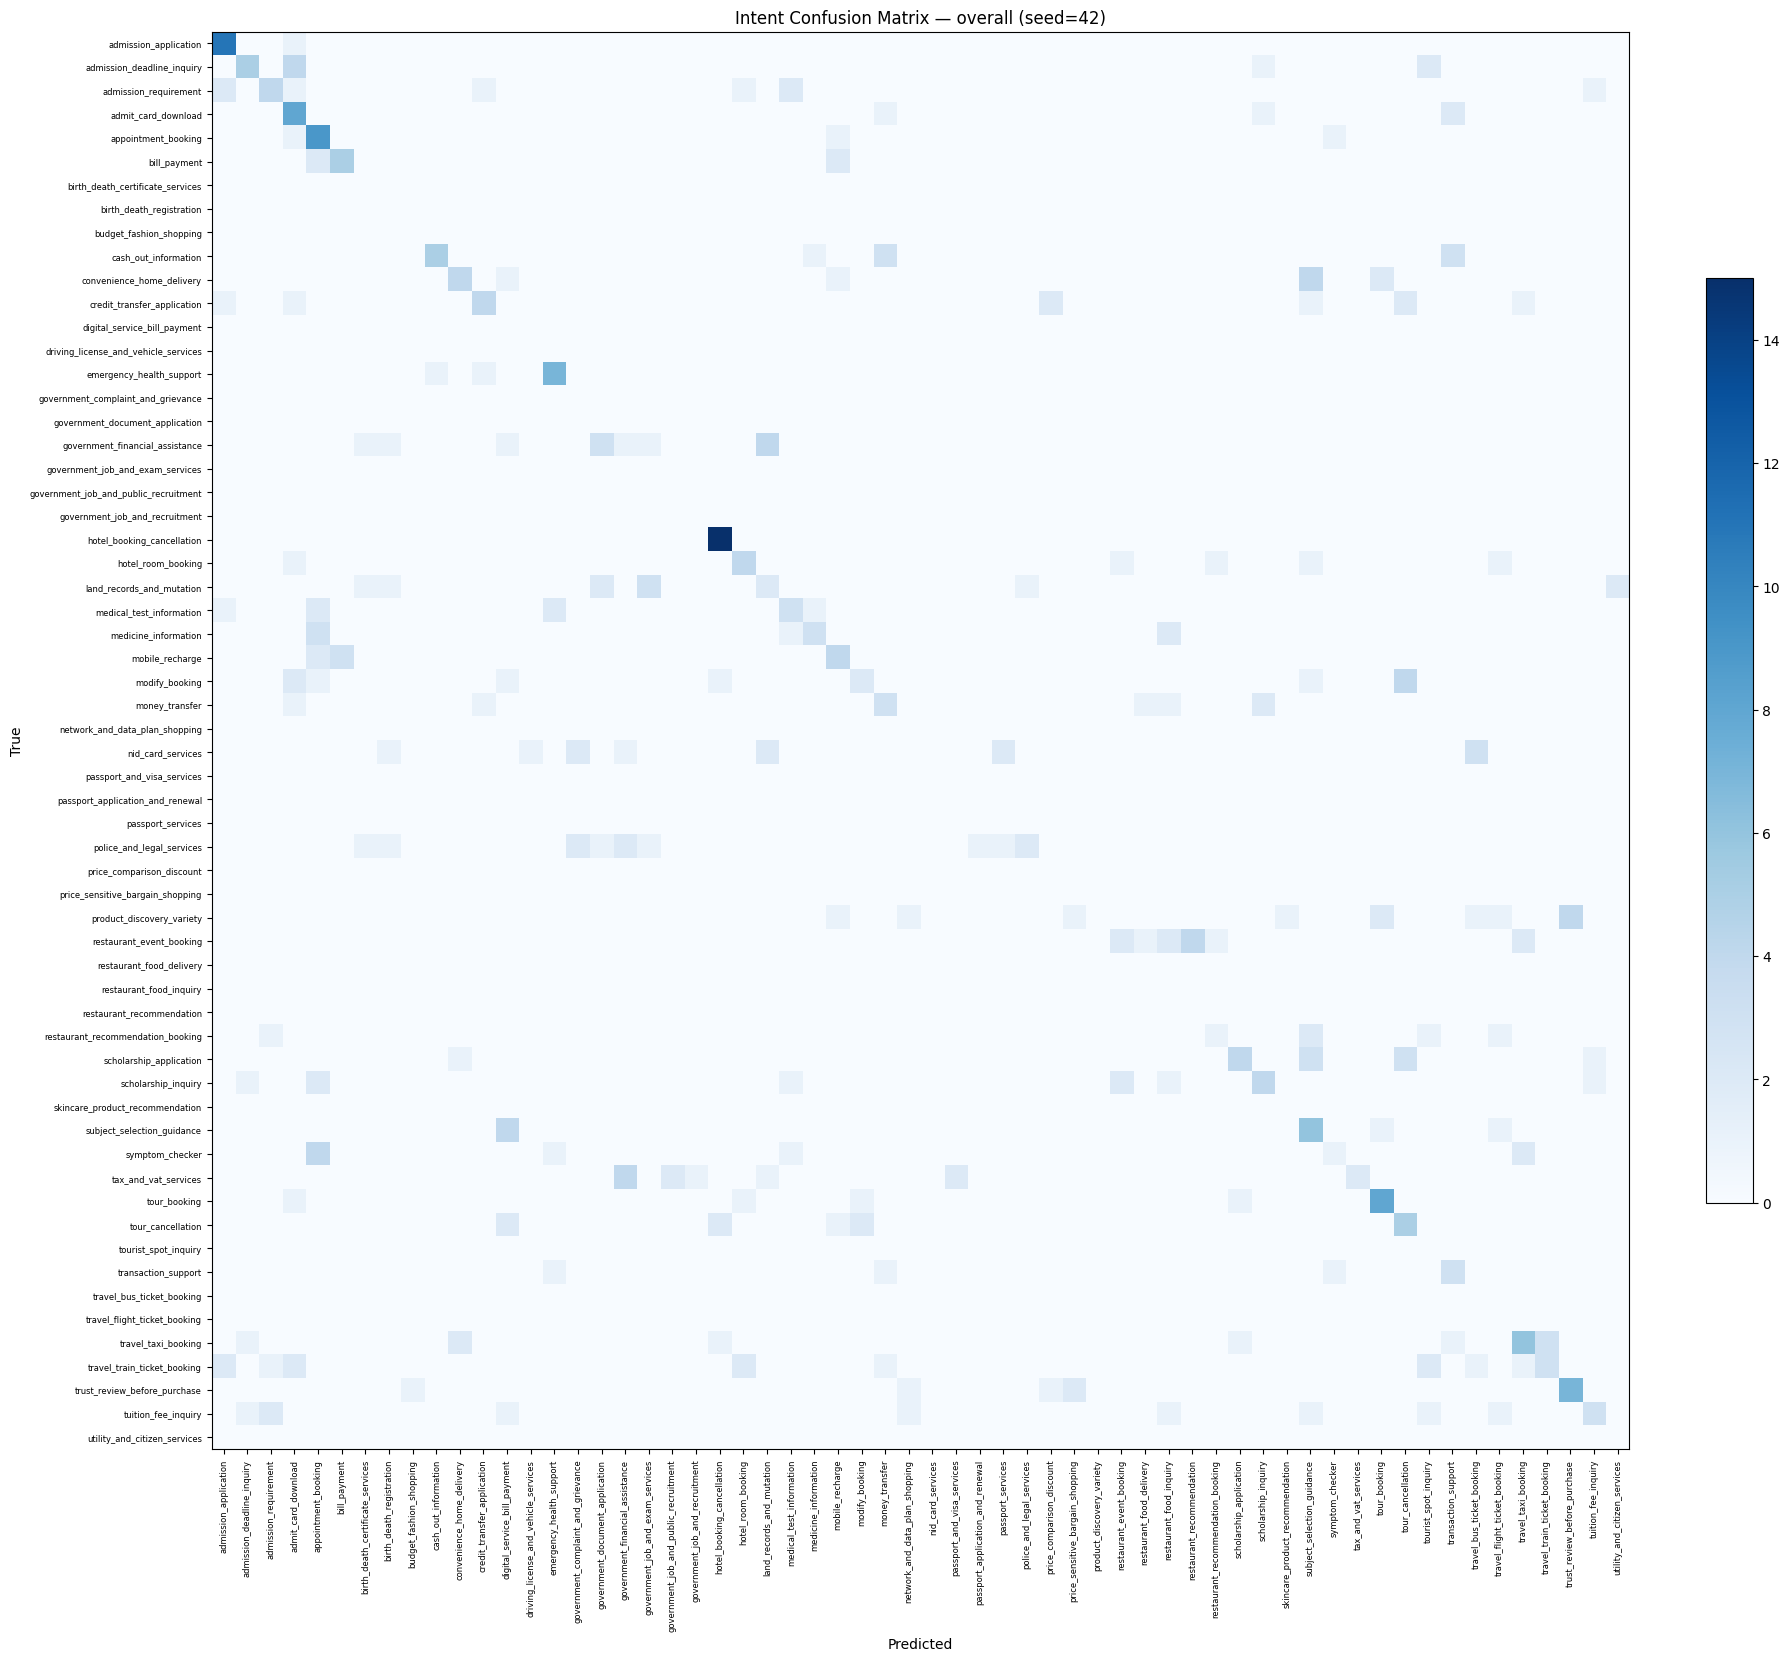


Slot TYPE confusion matrix (top 15 types, collapsed B-/I-, as a table)


,O,requested_information,tour_type,query,service,budget,pickup_address,payment_method,application_status,location,room_size,room_type,feature_query,education_background,email,OTHER
O,2432,12,0,3,11,1,1,2,0,2,0,1,4,0,1,96
requested_information,47,18,0,0,0,0,0,0,0,0,0,0,0,0,0,0
tour_type,28,0,6,0,0,0,0,0,0,0,0,0,0,0,0,11
query,27,0,0,9,0,0,0,0,0,0,0,0,0,0,0,0
service,5,0,0,0,19,0,0,0,0,0,0,0,0,0,0,0
budget,10,0,0,0,0,8,0,0,0,0,0,0,0,0,0,5
pickup_address,17,0,0,0,0,0,4,0,0,0,0,0,0,0,0,2
payment_method,10,0,0,0,0,0,0,5,0,0,0,0,0,0,0,0
application_status,15,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
location,6,0,0,0,0,0,0,0,0,4,0,0,0,0,0,4


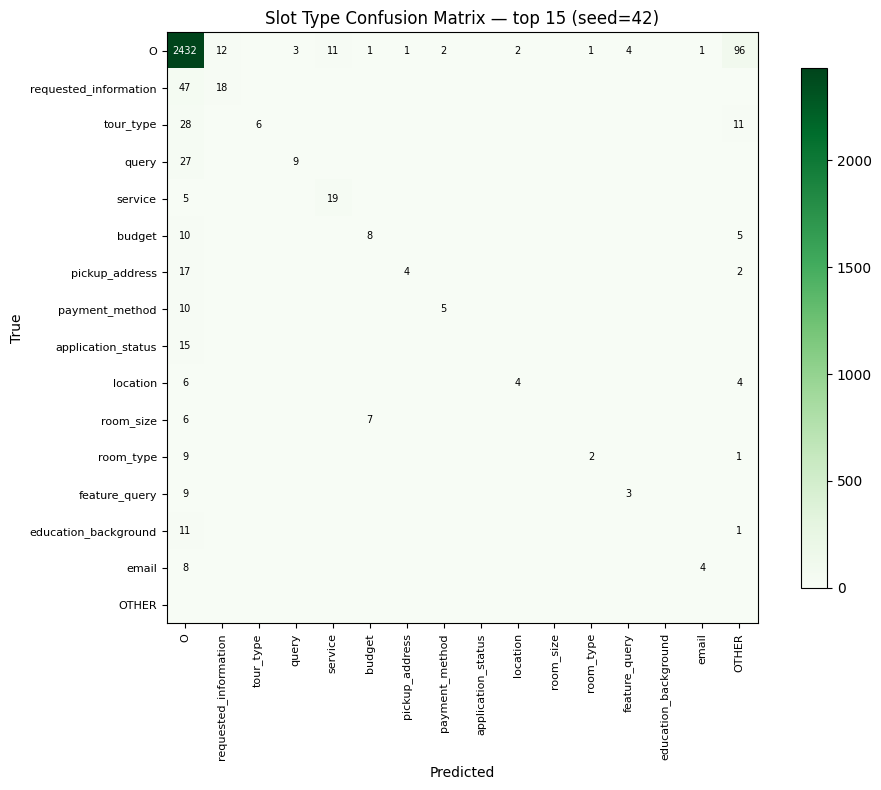


TABLE 6 — Top-5 most confused INTENT pairs per language (true -> predicted, count)

[bangla]


,true -> predicted,count
0,"(tour_cancellation, modify_booking)",2
1,"(tax_and_vat_services, government_financial_as...",2
2,"(government_financial_assistance, government_d...",2
3,"(land_records_and_mutation, utility_and_citize...",2
4,"(symptom_checker, appointment_booking)",2



[english]


,true -> predicted,count
0,"(restaurant_event_booking, restaurant_recommen...",2
1,"(travel_train_ticket_booking, admission_applic...",2
2,"(modify_booking, admit_card_download)",2
3,"(modify_booking, tour_cancellation)",2
4,"(convenience_home_delivery, subject_selection_...",2



[banglish]


,true -> predicted,count
0,"(product_discovery_variety, trust_review_befor...",3
1,"(restaurant_event_booking, restaurant_recommen...",2
2,"(travel_train_ticket_booking, hotel_room_booking)",2
3,"(travel_taxi_booking, convenience_home_delivery)",2
4,"(travel_taxi_booking, travel_train_ticket_book...",2



All metric tables and confusion matrices saved under: /content/outputs/context_banglabert_run_20260927_125848_seed42


In [23]:
# ============================================================
# CELL 7b — ALL METRICS in tabular form + confusion matrices
# Uses the best-of-seeds checkpoint already loaded in Cell 7 (`model`),
# and the test set already built in Cell 6 (`test_ds`, `test_loader`).
# Nothing here changes training — pure reporting/analysis.
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 200)

# ---- get fresh predictions from the best-seed model on the test set ----
raw_test, _ = predict_loader(model, test_loader, len(test_ds))
TEST_P = build_pred_records(raw_test, test_ds)
print(f"Using best seed = {best_seed} | test examples = {len(TEST_P)}")

# =========================================================================
# TABLE 1 — Master metrics table: overall + per language, single best model
# =========================================================================
scopes = {"overall": TEST_P}
for lg in LANGS:
    scopes[lg] = [p for p in TEST_P if p["lang"] == lg]

master_rows = []
for scope_name, P in scopes.items():
    m = compute_metrics(P)
    if m is None:
        continue
    master_rows.append({
        "Scope": scope_name,
        "N": m["n_samples"],
        "Intent Acc": m["intent_accuracy"],
        "Intent Micro-F1": m["intent_micro_f1"],
        "Intent Macro-F1": m["intent_macro_f1"],
        "Intent Weighted-F1": m["intent_weighted_f1"],
        "Domain Acc (derived)": m["domain_accuracy_derived_from_predicted_intent"],
        "Slot Token Acc (+O)": m["slot_token_accuracy"],
        "Slot Token Micro-F1": m["slot_token_micro_f1"],
        "Slot Token Macro-F1": m["slot_token_macro_f1"],
        "Slot Token Weighted-F1": m["slot_token_weighted_f1"],
        "Slot Entity Micro-F1": m["slot_entity_micro_f1"],
        "Slot Entity Macro-F1": m["slot_entity_macro_f1"],
        "Slot Entity Weighted-F1": m["slot_entity_weighted_f1"],
        "Joint Exact Match": m["joint_exact_match"],
    })

master_df = pd.DataFrame(master_rows).set_index("Scope")
print("\n" + "=" * 100)
print("TABLE 1 — MASTER METRICS (best-of-seeds model, single test run)")
print("=" * 100)
display(master_df.round(4))
master_df.to_csv(os.path.join(OUT_DIR, "master_metrics_table.csv"))

# =========================================================================
# TABLE 2 — Mean ± Std across all training seeds (re-shown here for convenience)
# =========================================================================
print("\n" + "=" * 100)
print("TABLE 2 — MEAN ± STD ACROSS SEEDS (from Cell 6b)")
print("=" * 100)
display(cross_seed_tbl.round(4))

# =========================================================================
# TABLE 3 — Intent classification report (per-class precision/recall/F1/support)
# =========================================================================
it, ip = [p["intent_true"] for p in TEST_P], [p["intent_pred"] for p in TEST_P]
li = sorted(set(it) | set(ip))
intent_report = classification_report(it, ip, labels=li, output_dict=True, zero_division=0)
intent_report_df = pd.DataFrame(intent_report).T
intent_report_df = intent_report_df.sort_values("support", ascending=False)
print("\n" + "=" * 100)
print("TABLE 3 — INTENT classification report (per class, sorted by support)")
print("=" * 100)
display(intent_report_df.round(4))
intent_report_df.to_csv(os.path.join(OUT_DIR, "intent_classification_report_table.csv"))

# =========================================================================
# TABLE 4 — Slot TOKEN-level classification report (BIO, includes O)
# =========================================================================
ft = [t for p in TEST_P for t in p["slot_true"]]
fp = [t for p in TEST_P for t in p["slot_pred"]]
ls = sorted(set(ft) | set(fp))
slot_token_report = classification_report(ft, fp, labels=ls, output_dict=True, zero_division=0)
slot_token_df = pd.DataFrame(slot_token_report).T.sort_values("support", ascending=False)
print("\n" + "=" * 100)
print("TABLE 4 — SLOT TOKEN-level classification report (top 20 by support, 'O' included)")
print("=" * 100)
display(slot_token_df.head(20).round(4))
slot_token_df.to_csv(os.path.join(OUT_DIR, "slot_token_classification_report_table.csv"))

# =========================================================================
# TABLE 5 — Slot ENTITY-level (whole-span) report, per slot type
# =========================================================================
overall_m = compute_metrics(TEST_P)
entity_per_type_df = pd.DataFrame(overall_m["entity_per_type"]).T.sort_values("support", ascending=False)
print("\n" + "=" * 100)
print("TABLE 5 — SLOT ENTITY-level report (whole-span correctness, per slot type)")
print("=" * 100)
display(entity_per_type_df.round(4))
entity_per_type_df.to_csv(os.path.join(OUT_DIR, "slot_entity_per_type_table.csv"))

# =========================================================================
# CONFUSION MATRIX 1 — Intent (overall)
# =========================================================================
ci = confusion_matrix(it, ip, labels=li)
ci_df = pd.DataFrame(ci, index=li, columns=li)

fig, ax = plt.subplots(figsize=(max(10, 0.3 * len(li)), max(8, 0.3 * len(li))))
im = ax.imshow(ci, cmap="Blues")
fig.colorbar(im, ax=ax, fraction=0.03)
ax.set_xticks(range(len(li))); ax.set_yticks(range(len(li)))
ax.set_xticklabels(li, rotation=90, fontsize=6)
ax.set_yticklabels(li, fontsize=6)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"Intent Confusion Matrix — overall (seed={best_seed})")
plt.tight_layout()
plt.show()
ci_df.to_csv(os.path.join(OUT_DIR, "intent_confusion_matrix_table.csv"))

# =========================================================================
# CONFUSION MATRIX 2 — Slot TYPE (collapsed B-/I- -> base type + O), top-15
# =========================================================================
def base_type(lbl):
    return "O" if lbl == "O" else lbl.split("-", 1)[1]

true_types = [base_type(t) for t in ft]
pred_types = [base_type(t) for t in fp]
top_types = [t for t, _ in Counter(true_types).most_common(15)]
mask = [i for i, t in enumerate(true_types) if t in top_types]
tt = [true_types[i] for i in mask]
pt = [pred_types[i] if pred_types[i] in top_types else "OTHER" for i in mask]
labels_st = top_types + ["OTHER"]
cs = confusion_matrix(tt, pt, labels=labels_st)
cs_df = pd.DataFrame(cs, index=labels_st, columns=labels_st)

print("\n" + "=" * 100)
print("Slot TYPE confusion matrix (top 15 types, collapsed B-/I-, as a table)")
print("=" * 100)
display(cs_df)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(cs, cmap="Greens")
fig.colorbar(im, ax=ax, fraction=0.03)
ax.set_xticks(range(len(labels_st))); ax.set_yticks(range(len(labels_st)))
ax.set_xticklabels(labels_st, rotation=90, fontsize=8)
ax.set_yticklabels(labels_st, fontsize=8)
for i in range(len(labels_st)):
    for j in range(len(labels_st)):
        v = cs[i, j]
        if v:
            ax.text(j, i, int(v), ha="center", va="center", fontsize=7,
                    color="white" if v > cs.max() * 0.6 else "black")
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"Slot Type Confusion Matrix — top 15 (seed={best_seed})")
plt.tight_layout()
plt.show()
cs_df.to_csv(os.path.join(OUT_DIR, "slot_type_confusion_matrix_table.csv"))

# =========================================================================
# TABLE 6 — Per-language confusion matrix summary (biggest confusions only)
# =========================================================================
print("\n" + "=" * 100)
print("TABLE 6 — Top-5 most confused INTENT pairs per language (true -> predicted, count)")
print("=" * 100)
for lg in LANGS:
    P_lg = [p for p in TEST_P if p["lang"] == lg]
    if not P_lg:
        continue
    it_lg = [p["intent_true"] for p in P_lg]; ip_lg = [p["intent_pred"] for p in P_lg]
    confusions = Counter((t, pr) for t, pr in zip(it_lg, ip_lg) if t != pr)
    top5 = confusions.most_common(5)
    df = pd.DataFrame(top5, columns=["true -> predicted", "count"])
    print(f"\n[{lg}]")
    display(df)

print("\nAll metric tables and confusion matrices saved under:", OUT_DIR)

In [24]:
from scipy import stats

# Example: is English intent accuracy significantly different from Bangla's, across seeds?
bangla_vals = cross_seed_stats["bangla"]["intent_accuracy"]["values"]
english_vals = cross_seed_stats["english"]["intent_accuracy"]["values"]
t_stat, p_val = stats.ttest_ind(bangla_vals, english_vals)
print(f"Bangla vs English intent accuracy: t={t_stat:.3f}, p={p_val:.3f}")

Bangla vs English intent accuracy: t=12.967, p=0.000


Error analysis: qualitative examples, not just numbers

In [25]:
wrong_intent = [p for p in TEST_P if p["intent_true"] != p["intent_pred"]]
print(f"{len(wrong_intent)} / {len(TEST_P)} intent errors\n")
for p in wrong_intent[:8]:
    print(f"[{p['lang']}] true={p['intent_true']}  pred={p['intent_pred']}")
    print(f"  words: {' '.join(p['words'])}\n")

249 / 405 intent errors

[bangla] true=restaurant_recommendation_booking  pred=travel_flight_ticket_booking
  words: হ্যাঁ , ধানমন্ডির ।

[english] true=restaurant_recommendation_booking  pred=admission_requirement
  words: Bro , is there any good restaurant around Dhanmondi ? Looking for good food at a low cost .

[english] true=restaurant_recommendation_booking  pred=subject_selection_guidance
  words: Yes , Dhanmondi .

[banglish] true=restaurant_recommendation_booking  pred=tourist_spot_inquiry
  words: Vai Dhanmondir ashepashe valo kono restaurant ache ? Ektu kom khorche valo khabar khujchi .

[banglish] true=restaurant_recommendation_booking  pred=subject_selection_guidance
  words: Ha , Dhanmondi .

[bangla] true=restaurant_event_booking  pred=restaurant_food_inquiry
  words: প্রায় ৮০ থেকে ১০০ জন হবে । ডেকোরেশন ও ব্যাকগ্রাউন্ড মিউজিক চাই ।

[bangla] true=restaurant_event_booking  pred=restaurant_recommendation_booking
  words: পরের মাসের ১৫ তারিখে বুক করা যাবে ?

[english] true

4. Context ablation: does context actually help, quantitatively?

In [27]:
# Build a no-context version of the test set and compare metrics head-to-head
test_ds_nocontext = ContextNLUDataset(SPLITS["test"], CONFIG["context_turns"], CONFIG["max_len"], use_context=False)
test_loader_nocontext = make_loader(test_ds_nocontext, CONFIG["eval_batch_size"], False)

raw_nc, _ = predict_loader(model, test_loader_nocontext, len(test_ds_nocontext))
TEST_P_NC = build_pred_records(raw_nc, test_ds_nocontext)
m_nc = compute_metrics(TEST_P_NC)
m_ctx = compute_metrics(TEST_P)

compare_df = pd.DataFrame({
    "With context": {"Intent Acc": m_ctx["intent_accuracy"], "Slot Token Macro-F1": m_ctx["slot_token_macro_f1"], "Joint EM": m_ctx["joint_exact_match"]},
    "Without context": {"Intent Acc": m_nc["intent_accuracy"], "Slot Token Macro-F1": m_nc["slot_token_macro_f1"], "Joint EM": m_nc["joint_exact_match"]},
}).T
display(compare_df.round(4))

,Intent Acc,Slot Token Macro-F1,Joint EM
With context,0.3852,0.1275,0.1136
Without context,0.1951,0.1061,0.0395


In [30]:
# ============================================================
# CELL 7c — Trivial baselines (majority-class), for context on how "good" the real numbers are
# ============================================================
from collections import Counter

def majority_baseline_metrics(train_records, test_P):
    # Intent: always predict the most common training intent
    majority_intent = Counter(r["intent"] for r in train_records).most_common(1)[0][0]
    it = [p["intent_true"] for p in test_P]
    ip_baseline = [majority_intent] * len(it)

    # Slot: always predict "O" everywhere (never find any slot)
    ft = [t for p in test_P for t in p["slot_true"]]
    fp_baseline = ["O"] * len(ft)

    li = sorted(set(it) | {majority_intent})
    intent_acc = accuracy_score(it, ip_baseline)
    intent_macro = f1_score(it, ip_baseline, labels=li, average="macro", zero_division=0)

    ls = sorted(set(ft) | {"O"})
    slot_acc = accuracy_score(ft, fp_baseline)
    slot_macro = f1_score(ft, fp_baseline, labels=ls, average="macro", zero_division=0)

    return {"majority_intent": majority_intent, "intent_accuracy": intent_acc, "intent_macro_f1": intent_macro,
            "slot_token_accuracy": slot_acc, "slot_token_macro_f1": slot_macro}

baseline = majority_baseline_metrics(SPLITS["train"], TEST_P)
real = compute_metrics(TEST_P)

compare_df = pd.DataFrame({
    "Majority-class baseline": {"Intent Acc": baseline["intent_accuracy"], "Intent Macro-F1": baseline["intent_macro_f1"],
                                 "Slot Acc": baseline["slot_token_accuracy"], "Slot Macro-F1": baseline["slot_token_macro_f1"]},
    "Your model": {"Intent Acc": real["intent_accuracy"], "Intent Macro-F1": real["intent_macro_f1"],
                   "Slot Acc": real["slot_token_accuracy"], "Slot Macro-F1": real["slot_token_macro_f1"]},
}).T
print(f"Majority intent in training data: '{baseline['majority_intent']}'")
display(compare_df.round(4))

Majority intent in training data: 'scholarship_application'


,Intent Acc,Intent Macro-F1,Slot Acc,Slot Macro-F1
Majority-class baseline,0.0296,0.0016,0.7453,0.0048
Your model,0.3852,0.2368,0.7511,0.1275


In [31]:
def bootstrap_ci(P, metric_fn, n_boot=1000, seed=42):
    rng = np.random.RandomState(seed)
    n = len(P)
    scores = []
    for _ in range(n_boot):
        idx = rng.randint(0, n, n)
        sample = [P[i] for i in idx]
        scores.append(metric_fn(sample))
    return np.percentile(scores, 2.5), np.mean(scores), np.percentile(scores, 97.5)

intent_acc_fn = lambda P: accuracy_score([p["intent_true"] for p in P], [p["intent_pred"] for p in P])
lo, mean, hi = bootstrap_ci(TEST_P, intent_acc_fn)
print(f"Intent accuracy: {mean:.3f}  (95% CI: {lo:.3f} – {hi:.3f})")

Intent accuracy: 0.386  (95% CI: 0.341 – 0.435)


In [ ]:
import shutil
zip_path = shutil.make_archive(OUT_DIR, 'zip', OUT_DIR)
print("Saved zip:", zip_path)

try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    # On Kaggle: files placed under /kaggle/working are automatically
    print("On Kaggle, find your zip under Output once the notebook finishes:")
    print(" ", zip_path)